# Notebook 1 · Aplicação multiambientes e conferência documental · v09

**CIV2155 · FNDE Tipo 2 · IFC de arquitetura ARQ-DTV R03.**

Aplicamos o núcleo consolidado aos **41 IfcSpace**: cozinha de controle e os outros 40. Todos recebem um registro, inclusive os que o preparo não consegue processar. A rotina usa GUIDs e parâmetros comuns; não seleciona regras ou tolerâncias pelo nome do cômodo.

Separamos duas avaliações: **cobertura computacional dos 41 espaços** e **conferência documental de uma amostra intencional de 14 ambientes**, com 13 além da cozinha. A referência não entra na previsão. Ela foi construída por leitura visual assistida por IA, não em avaliação cega de especialista.

**Resultado a verificar:** 29 espaços chegam à associação e 12 ficam inconclusivos no preparo. Na amostra, são 35 associações corretas e 33 exclusões corretas; oito referências positivas não são recuperadas por causa do preparo de três ambientes. O conflito JA-09 da cozinha permanece indeterminado.

As versões anteriores continuam preservadas. Esta revisão reorganiza o Notebook 1 para a execução em lote e mantém o grafo completo v08 como base.

## Referências e função efetiva de cada método

| Fonte | Uso nesta revisão |
|---|---|
| [Bonduel et al. (2018), IFCtoLBD](https://ceur-ws.org/Vol-2159/04paper.pdf) | Conversão semântica e correção textual anteriores preservadas na base v08; Java não reexecutado. |
| [Fichter et al. (2021), IFC2SB](https://doi.org/10.26868/25222708.2021.30156) | Helper parcial de recortes, ancestralidade e preparo Sewing/MakeSolid. Cada parede é preparada uma vez, com atribuição GPL preservada. |
| [Kiavarz et al. (2023)](https://doi.org/10.3390/buildings13020350) | Interfaces por projeção/interseção de faces, orientação, raios e sondas, com as adaptações já registradas dos §§4.2.2–4.4. |
| [Krijnen et al. (2020)](https://doi.org/10.46421/2706-6568.37.2020.paper008) | Referência e diagnósticos anteriores preservados. CGAL/Nef não reexecutado e seus resultados da cozinha não são transplantados aos novos pares. |
| [Lilis et al. (2026)](https://doi.org/10.1016/j.autcon.2026.106840) | Operadores comparativos e referências mantidos; 20 controles repetidos. O fluxo do artigo, incluindo alpha wrap, não é executado no lote. |
| [Zhang et al. (2018), GEOM/BimSPARQL](https://doi.org/10.3233/SW-180297) | Coordenadas e geometrias RDF. |
| [FNDE, Projeto Tipo 2 R03](https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/proinfancia/projetos-arquitetonicos-para-construcao/projeto-tipo-2) | Pranchas 02, 20 e 24–27 para a amostra documental. |

O preparo compartilhado, a execução em lote, as regras de candidatos internos/componentes e a avaliação são adaptações específicas deste estudo. A comparação de volumes entre espaços usa **Common OCP atual**, sem atribuí-la ao motor CGAL/Nef. Fontes técnicas: [IfcOpenShell](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html), [OCP](https://github.com/CadQuery/OCP), [Shapely](https://shapely.readthedocs.io/en/stable/reference/shapely.intersection.html) e [RDFLib](https://rdflib.readthedocs.io/en/stable/intro_to_graphs/).

## 1. Preparar bibliotecas e diretório de trabalho

A execução registrada usa um novo kernel. As bibliotecas são importadas antes do código do pacote. As versões efetivas serão registradas no final; as geometrias preparadas têm versão do motor e hashes próprios.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,zipfile,shutil,subprocess,importlib.util
from urllib.request import urlretrieve
deps={'numpy':'numpy','ifcopenshell':'ifcopenshell==0.8.4','OCP':'cadquery-ocp==7.8.1.1.post1','shapely':'shapely==2.2.0','rdflib':'rdflib==7.1.4','matplotlib':'matplotlib==3.10.7'}
missing=[p for m,p in deps.items() if importlib.util.find_spec(m) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
import ifcopenshell,OCP,numpy,shapely,rdflib,matplotlib
RAIZ=Path(os.environ.get('CIV2155_MULTI_RAIZ','CIV2155_Notebook1_v09')).resolve()
RAIZ.mkdir(parents=True,exist_ok=True)
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
print('IfcOpenShell',ifcopenshell.version,'OCP',OCP.__version__,'Shapely',shapely.__version__)


IfcOpenShell 0.8.4 OCP 7.8.1.1 Shapely 2.2.0


## 2. Importar fontes e entradas verificadas

São três pacotes independentes: código/entradas/referências; preparo geométrico; e grafo completo v08. Todos vêm de uma revisão fixa e são verificados por SHA-256. O IFC original é importado separadamente e não será regravado.

O preparo global foi **efetivamente executado nesta revisão** antes de gerar o pacote: 41 espaços, 457 paredes, 184 aberturas e 188 produtos de preenchimento/componentes examinados. Cada recorte de parede fica disponível para todos os cômodos, evitando repetir a mesma operação. Nesta execução do notebook, o preparo é reutilizado por hash; a associação aos espaços será executada novamente.

`REPROCESSAR_PREPARO=True` permite refazer o preparo diretamente do IFC com o código incluído. O padrão preserva o preparo fixado, cuja versão e integridade são conferidas. As variáveis locais opcionais apenas substituem o download e não dispensam hashes.

In [2]:
SNAPSHOT='bf4ac2196303562bcecc14e742d64dccbfde2a39'
BASE='https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/'+SNAPSHOT+'/'
arquivos=[('CIV2155_MULTI_PACOTE','resultados/multiambientes_v01/Pacote_Codigo_Entradas_Multiambientes_v09.zip','3c2d2e25c81f150277b9211a0b0e9adcefa4f44fc7c36d0f06a92fc6872b7a39'),('CIV2155_MULTI_CACHE','resultados/multiambientes_v01/Pacote_Preparo_Geometrico_v09.zip','77cfddfad5ea191073d625916cd8c9a63d7df04364ea09e45dbd5899f7d47e66'),('CIV2155_MULTI_BASE','resultados/consolidacao_hibrido_v01/rdf_principal/Notebook1_Grafo_Completo_v08.zip','e2fd42069d6c0e32b968e83b2a40358acdbb5ebe469cd20eff2333f5a4b49e3b')]
locais=[]
for variavel,rel,digest in arquivos:
    destino=RAIZ/Path(rel).name
    local=os.environ.get(variavel)
    if local:shutil.copy2(local,destino)
    else:urlretrieve(BASE+rel,destino)
    assert sha(destino)==digest
    locais.append(destino)
for p in locais[:2]:
    with zipfile.ZipFile(p) as z:z.extractall(RAIZ)
BASE_V08=locais[2]
IFC=RAIZ/'TIPO2-ARQ-DTV_R03.ifc'
local=os.environ.get('CIV2155_MULTI_IFC')
if local:shutil.copy2(local,IFC)
else:
    compacto=RAIZ/'Arquitetura_Original.zip'
    urlretrieve(BASE+'dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip',compacto)
    with zipfile.ZipFile(compacto) as z:IFC.write_bytes(z.read(IFC.name))
IFC_SHA='0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a'
assert sha(IFC)==IFC_SHA
sys.path.insert(0,str(RAIZ/'codigo'))
CACHE=RAIZ/'cache';ENTRADA=RAIZ/'entrada';REF=RAIZ/'referencias'
SAIDA=RAIZ/'resultados';SAIDA.mkdir(exist_ok=True)
REPROCESSAR_PREPARO=False
if REPROCESSAR_PREPARO:
    from preparar_geometria import preparar
    preparar(IFC,CACHE,workers=2)
catalogo=json.loads((CACHE/'Catalogo_Geometria_v09.json').read_text(encoding='utf8'))
assert catalogo['ifc_sha256']==IFC_SHA
assert ifcopenshell.version==catalogo['ifcopenshell'] and OCP.__version__==catalogo['OCP'],'Versões diferentes do preparo: revisar o ambiente ou regenerar as geometrias.'
modelo=ifcopenshell.open(str(IFC))
assert {r['guid'] for r in catalogo['espacos']}=={r.GlobalId for r in modelo.by_type('IfcSpace')}
print('Todos os 41 IfcSpace estão no catálogo. Preparo:',json.dumps(catalogo['resumo'],ensure_ascii=False))


Todos os 41 IfcSpace estão no catálogo. Preparo: {"espacos": 41, "espacos_com_volume_aceito": 29, "paredes": 457, "paredes_preparadas": 453, "paredes_inconclusivas": 4, "aberturas_ifc": 184, "produtos_examinados": 188}


## 3. Repetir os controles dos operadores

São 17 controles da adaptação parcial IFC2SB, 17 de faces/projeções Kiavarz e 20 de operadores Lilis. A referência C++ usada nos controles IFC2SB foi compilada e arquivada anteriormente; não é recompilada nesta célula. Repetir controles Lilis não significa aplicar seu método completo ao edifício.

In [3]:
from testar_adaptacao import run as testar_ifc2sb
from testar_faces import run as testar_kiavarz
from controles_lilis import run as testar_lilis
controles=SAIDA/'controles'
c1=testar_ifc2sb(RAIZ/'codigo/referencia_cpp/Resultado_CPP.json',controles/'ifc2sb')
c2=testar_kiavarz(controles/'kiavarz')
c3=testar_lilis(controles/'lilis')
assert [c1['aprovados'],c2['aprovados'],c3['aprovados']]==[17,17,20]
print('54 controles dos operadores aprovados.')


CONTROLES 17 / 17
CONTROLES 17 / 17
Controles Lilis: 20 aprovados
54 controles dos operadores aprovados.


## 4. Aplicar a mesma rotina aos 41 ambientes

`executar_lote(IFC, CACHE, SAIDA)` percorre todos os espaços e mantém os estados de processamento. Não há bloqueio por GUID da cozinha. Para um único cômodo, pode-se usar `RotinaMultiambientes(CACHE).executar_ambiente(GUID, pasta)`.

Os filtros permanecem comuns: distância entre planos de 10⁻⁴ m, área mínima de 10⁻⁸ m², orientação das faces e sondas locais de 1 mm, com sensibilidade em 0,1 e 2 mm. Os recortes IFC2SB são cruzados com a interface específica do espaço e seu contorno parental.

O preparo de cada espaço exige uma única casca fechada, válida e sem descarte de faces. Caso não seja aceito, a quantidade de esquadrias é **indisponível**, em vez de zero. Não são feitas reparações globais ou substituição por caixa.

As saídas distinguem esquadrias em limites, outros preenchimentos, internos candidatos e componentes sem FillsVoids. As regras candidatas de internos/componentes são as da v08 e não certificam função arquitetônica. Uma porta compartilhada pode aparecer em dois ambientes: pares ambiente–esquadria não são quantidades de peças.

In [4]:
from rotina_multiambientes import executar_lote
lote=executar_lote(IFC,CACHE,SAIDA)
assert lote['espacos_solicitados']==41
assert lote['espacos_com_associacao_executada']==29 and lote['espacos_inconclusivos']==12
assert lote['pares_ambiente_esquadria']==74 and lote['esquadrias_distintas_associadas']==57
assert lote['ifc_original_preservado']
print('A referência documental ainda não foi usada na previsão.')


AMBIENTE 1 / 41 INFANTIL 1 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 2 / 41 INFANTIL 2/3 associacao_executada_com_pendencias {'interfaces': 210, 'interfaces_qualificadas': 210, 'paredes_com_interface': 18, 'esquadrias': 3, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 27}


AMBIENTE 3 / 41 INFANTIL 4 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 4 / 41 INFANTIL 5 inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 5 / 41 SANIT. INFANTIL FEM. associacao_executada_com_pendencias {'interfaces': 373, 'interfaces_qualificadas': 373, 'paredes_com_interface': 25, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 2, 'componentes': 0, 'problemas': 27}


...

AMBIENTE 39 / 41 LIXO associacao_executada {'interfaces': 3, 'interfaces_qualificadas': 3, 'paredes_com_interface': 3, 'esquadrias': 2, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


AMBIENTE 40 / 41 FRALDÁRIO inconclusivo_preparacao_espaco {'interfaces': None, 'esquadrias': None, 'internos': None, 'componentes': None}


AMBIENTE 41 / 41 CIRCULAÇÃO associacao_executada {'interfaces': 36, 'interfaces_qualificadas': 36, 'paredes_com_interface': 3, 'esquadrias': 1, 'outros_preenchimentos': 0, 'internos': 0, 'componentes': 0, 'problemas': 0}


{
  "ifc_sha256": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "parametros_comuns": {
    "distancia_planos_m": 0.0001,
    "area_min_m2": 1e-08,
    "tol_normal": 1e-10,
    "sonda_principal_m": 0.001,
    "tolerancia_classificacao_m": 1e-07,
    "tolerancia_contorno_parental_m2": 1e-07,
    "tolerancia_internos_m": 1e-05,
    "distancia_componente_m": 0.25,
    "margem_componente_m": 0.02
  },
  "estados": {
    "inconclusivo_preparacao_espaco": 12,
    "associacao_executada_com_pendencias": 9,
    "associacao_executada": 20
  },
  "espacos_solicitados": 41,
  "espacos_com_associacao_executada": 29,
  "espacos_inconclusivos": 12,
  "pares_ambiente_esquadria": 74,
  "esquadrias_distintas_associadas": 57,
  "cache_catalogo_sha256": "bae608f6421a98d7c9b3c862ca4e2da87655f3367f76e789ada052743e784894",
  "preparo_global": {
    "espacos": 41,
    "espacos_com_volume_aceito": 29,
    "paredes": 457,
    "paredes_preparadas": 453,
    "paredes_inconclusivas": 4,
    

A referência documental ainda não foi usada na previsão.


## 5. Conferir documentos, sobreposições e regressão

A amostra documental intencional contém **13 novos ambientes e a cozinha**: despensa, copa, vestiários feminino/masculino, sanitários PCD feminino/masculino, sala de atendimento, sala de professores, lactário, Infantil 2/3, Administração, Infantil 1 e Lavanderia/Rouparia. Ela cobre usos diferentes e inclui casos inconclusivos; não é seleção aleatória ou avaliação cega.

As pranchas oficiais R03 02, 20 e 24–27 fornecem tipo, posição e vizinhança para identificar os objetos. Os GUIDs apenas estabelecem a correspondência ao IFC. A referência tem 43 pares positivos, 39 negativos e a JA-09 da cozinha indeterminada. O algoritmo de previsão não recebe esse arquivo.

Nos ambientes processados, distinguimos associação correta, indevida, omissão após associação e exclusão correta. Nos inconclusivos, o positivo fica como **não recuperado por preparo**; o negativo não é contado como exclusão correta. A JA-09 permanece fora dos denominadores de acerto. A conferência documental é assistida por IA e ainda precisa de revisão independente.

O diagnóstico volumétrico entre os espaços aceitos usa Common OCP e componentes sólidos. Não é CGAL/Nef e não implica execução do fluxo completo de Lilis. As sobreposições ficam registradas, sem vetar automaticamente toda abertura.

Cinco controles verificam que a cozinha preservou as nove esquadrias, 14 interfaces, dez internos, três componentes e a área das interfaces. Seis controles novos verificam cobertura dos 41 GUIDs, rejeição de GUID desconhecido, parâmetros comuns, inconclusão sem falso zero, isolamento entre cômodos e denominadores da avaliação.

In [5]:
from auditar_lote import auditar_sobreposicoes,conferir_documentos,regressao_cozinha
from testar_generalizacao import run as testar_generalizacao
sobreposicoes=auditar_sobreposicoes(CACHE,SAIDA/'diagnosticos')
conferencia=conferir_documentos(SAIDA,REF/'Referencia_Multiambientes_R03.json')
regressao=regressao_cozinha(SAIDA,ENTRADA/'Controle_Cozinha_v08.json')
c4=testar_generalizacao(IFC,CACHE,SAIDA,controles/'generalizacao')
t=conferencia['totais']
assert (t['TP'],t['FP'],t['FN'],t['TN'])==(35,0,0,33)
assert t['positivos_nao_recuperados_por_preparacao']==8 and t['negativos_nao_avaliaveis_por_preparacao']==6
assert conferencia['amostra_ambientes']==14 and conferencia['previsoes_fora_referencia']==0
assert sobreposicoes['pares_examinados']==406 and sobreposicoes['pares_com_sobreposicao']==12
assert sum(regressao.values())==5 and c4['aprovados']==6
print('Total de controles:',54+sum(regressao.values())+c4['aprovados'])


Sobreposições: 12 em 406 pares.
Conferência: {"amostra_ambientes": 14, "totais": {"TP": 35, "FP": 0, "FN": 0, "TN": 33, "indeterminados": 1, "positivos_nao_recuperados_por_preparacao": 8, "negativos_nao_avaliaveis_por_preparacao": 6}, "recuperacao_incluindo_inconclusivos": 0.813953488372093, "previsoes_fora_referencia": 0}
Regressão cozinha: 5 controles aprovados.


Generalização: 6 controles aprovados.


Total de controles: 65


## 6. Acrescentar os resultados ao grafo completo do Notebook 1

O complemento usa as identidades existentes do grafo principal, por GUID único do mesmo IFC. Cada espaço recebe um `mu:ResultadoPorAmbiente`, com estado, motivos e associações. Os identificadores das interfaces incluem o GUID do espaço, evitando misturar evidências de cômodos diferentes.

A base v08 é preservada byte a byte no novo Turtle. A união é reaberta e consultada: devem aparecer os 41 estados e os 74 pares. Nos 12 inconclusivos, a contagem permanece ausente. Os registros documentais são acrescentados como conferência posterior, sem alterar a previsão.

`mu:` identifica esta revisão e evita confundir seus resultados com consultas históricas. A quantidade de fragmentos de interface depende da segmentação do IFC, não equivale à quantidade de paredes físicas. O grafo grande é entregue compactado.

In [6]:
from integrar_lote_rdf import run as integrar
integracao=integrar(SAIDA,ENTRADA/'Identidades_N1.csv',BASE_V08,ENTRADA/'Registro_Base_v08.json',SAIDA/'rdf_principal')
assert integracao['espacos_consultados']==41 and integracao['pares_ambiente_esquadria_consultados']==74
assert integracao['inconclusivos_sem_contagem_falsa_zero']==12 and integracao['grafo_reaberto_e_consultado']
print('Base v08 preservada e consulta multiambientes aprovada.')


Reabrindo grafo completo v09 para consultar todos os espaços...


{
  "triplas_base_v08": 120191,
  "triplas_uniao_v09": 137832,
  "espacos_consultados": 41,
  "pares_ambiente_esquadria_consultados": 74,
  "interfaces_registradas": 1950,
  "inconclusivos_sem_contagem_falsa_zero": 12,
  "base_v08_preservada_bytes": 187127277,
  "sha256_base_v08": "caa11e9c3e0e196df14a3a3265b35498e6ad6b9b46d5df569cb9602887f5db14",
  "sha256_saida": "465d99d0a6276fa21de625ff1e4f3eb34b4bec992e5fd4d183a86c1411973b15",
  "grafo_reaberto_e_consultado": true,
  "limite": "Propriedades mu: identificam o resultado desta revisão; não substituem registros históricos nem certificam completude arquitetônica."
}
Base v08 preservada e consulta multiambientes aprovada.


## 7. Visualizar cobertura e conferência por ambiente

O primeiro quadro separa aplicação aos 41 espaços da conferência da amostra de 14. O segundo mostra as referências positivas por ambiente. Os oito positivos não recuperados em Administração, Infantil 1 e Lavanderia/Rouparia continuam visíveis; eles não são apagados para apresentar acerto perfeito.

O relatório inclui tabela de todos os cômodos, motivos dos inconclusivos, casos documentais, diagnósticos e ligações para pranchas e RDF. Os estados “associação executada” e “com pendências” descrevem a execução, sem certificar completude arquitetônica.

Figuras e relatório multiambientes gerados.


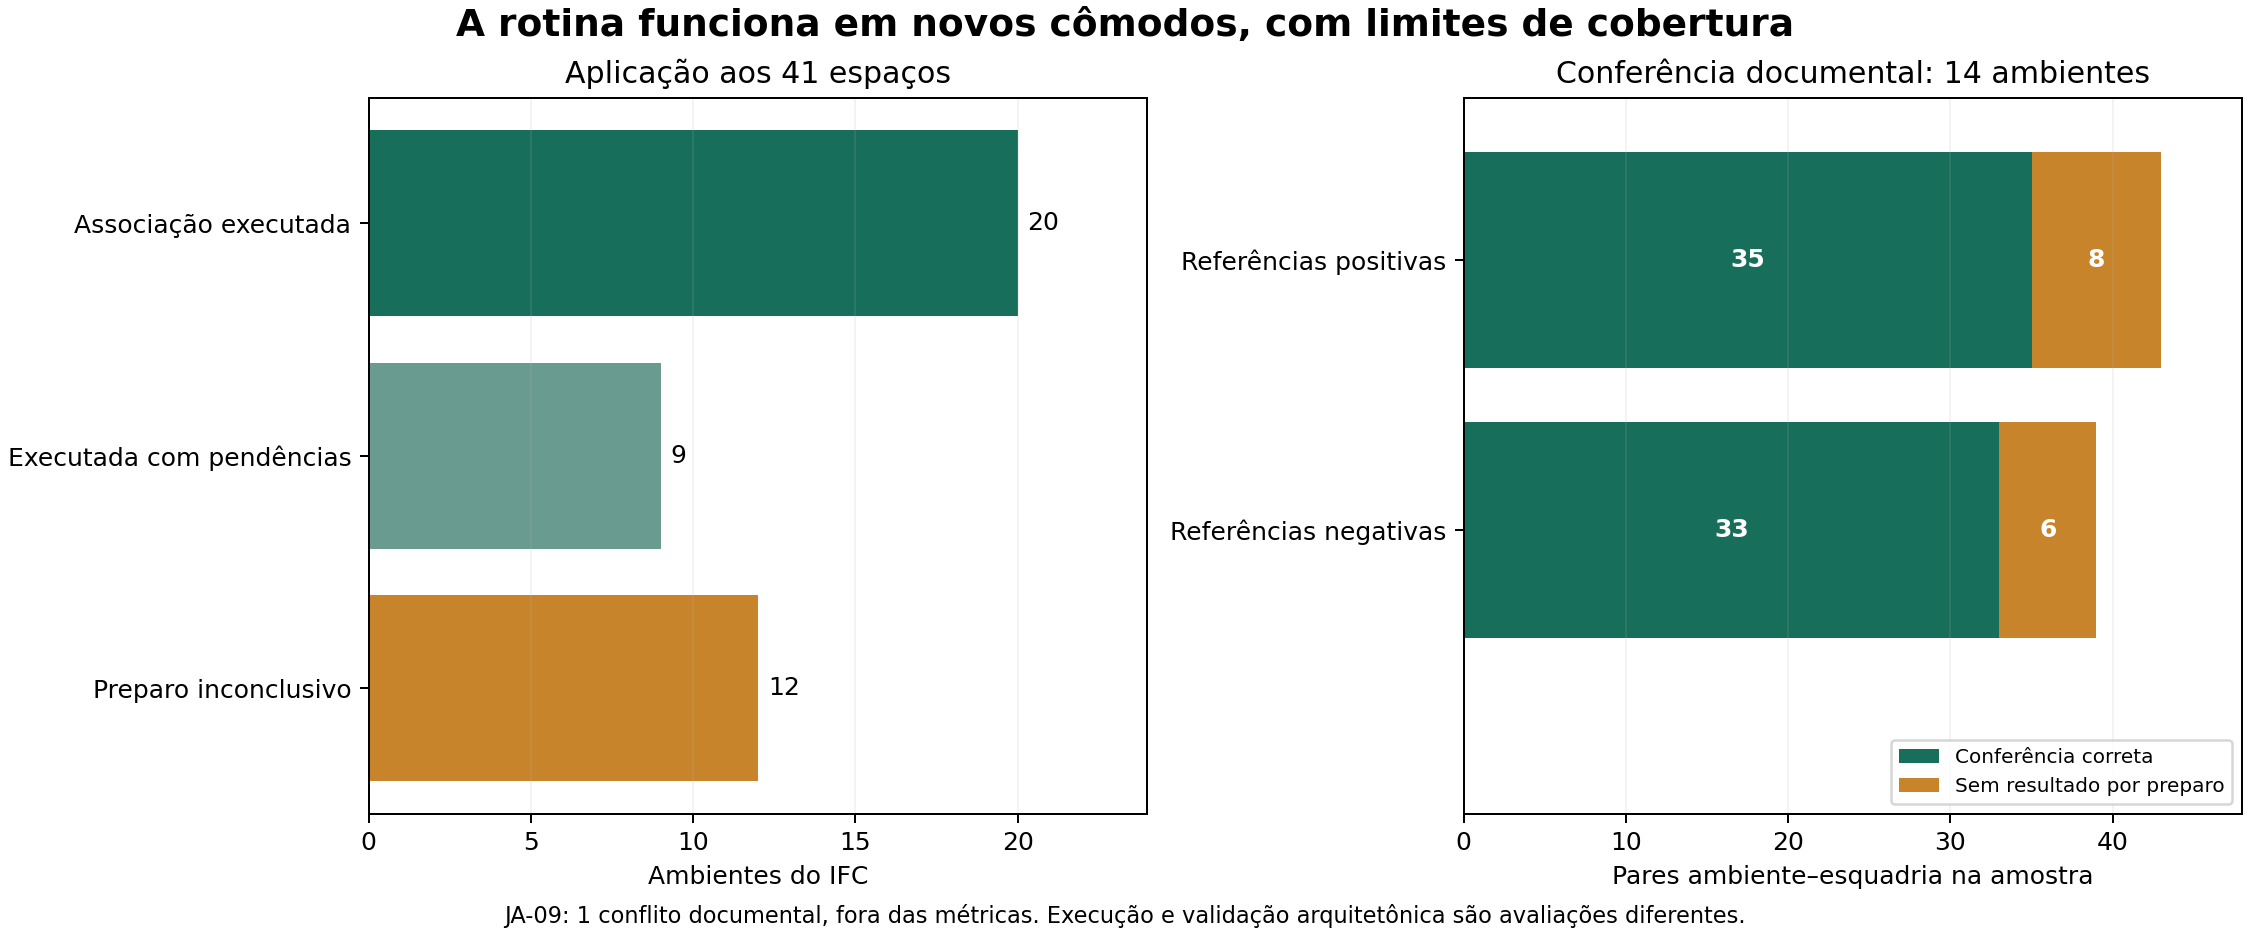

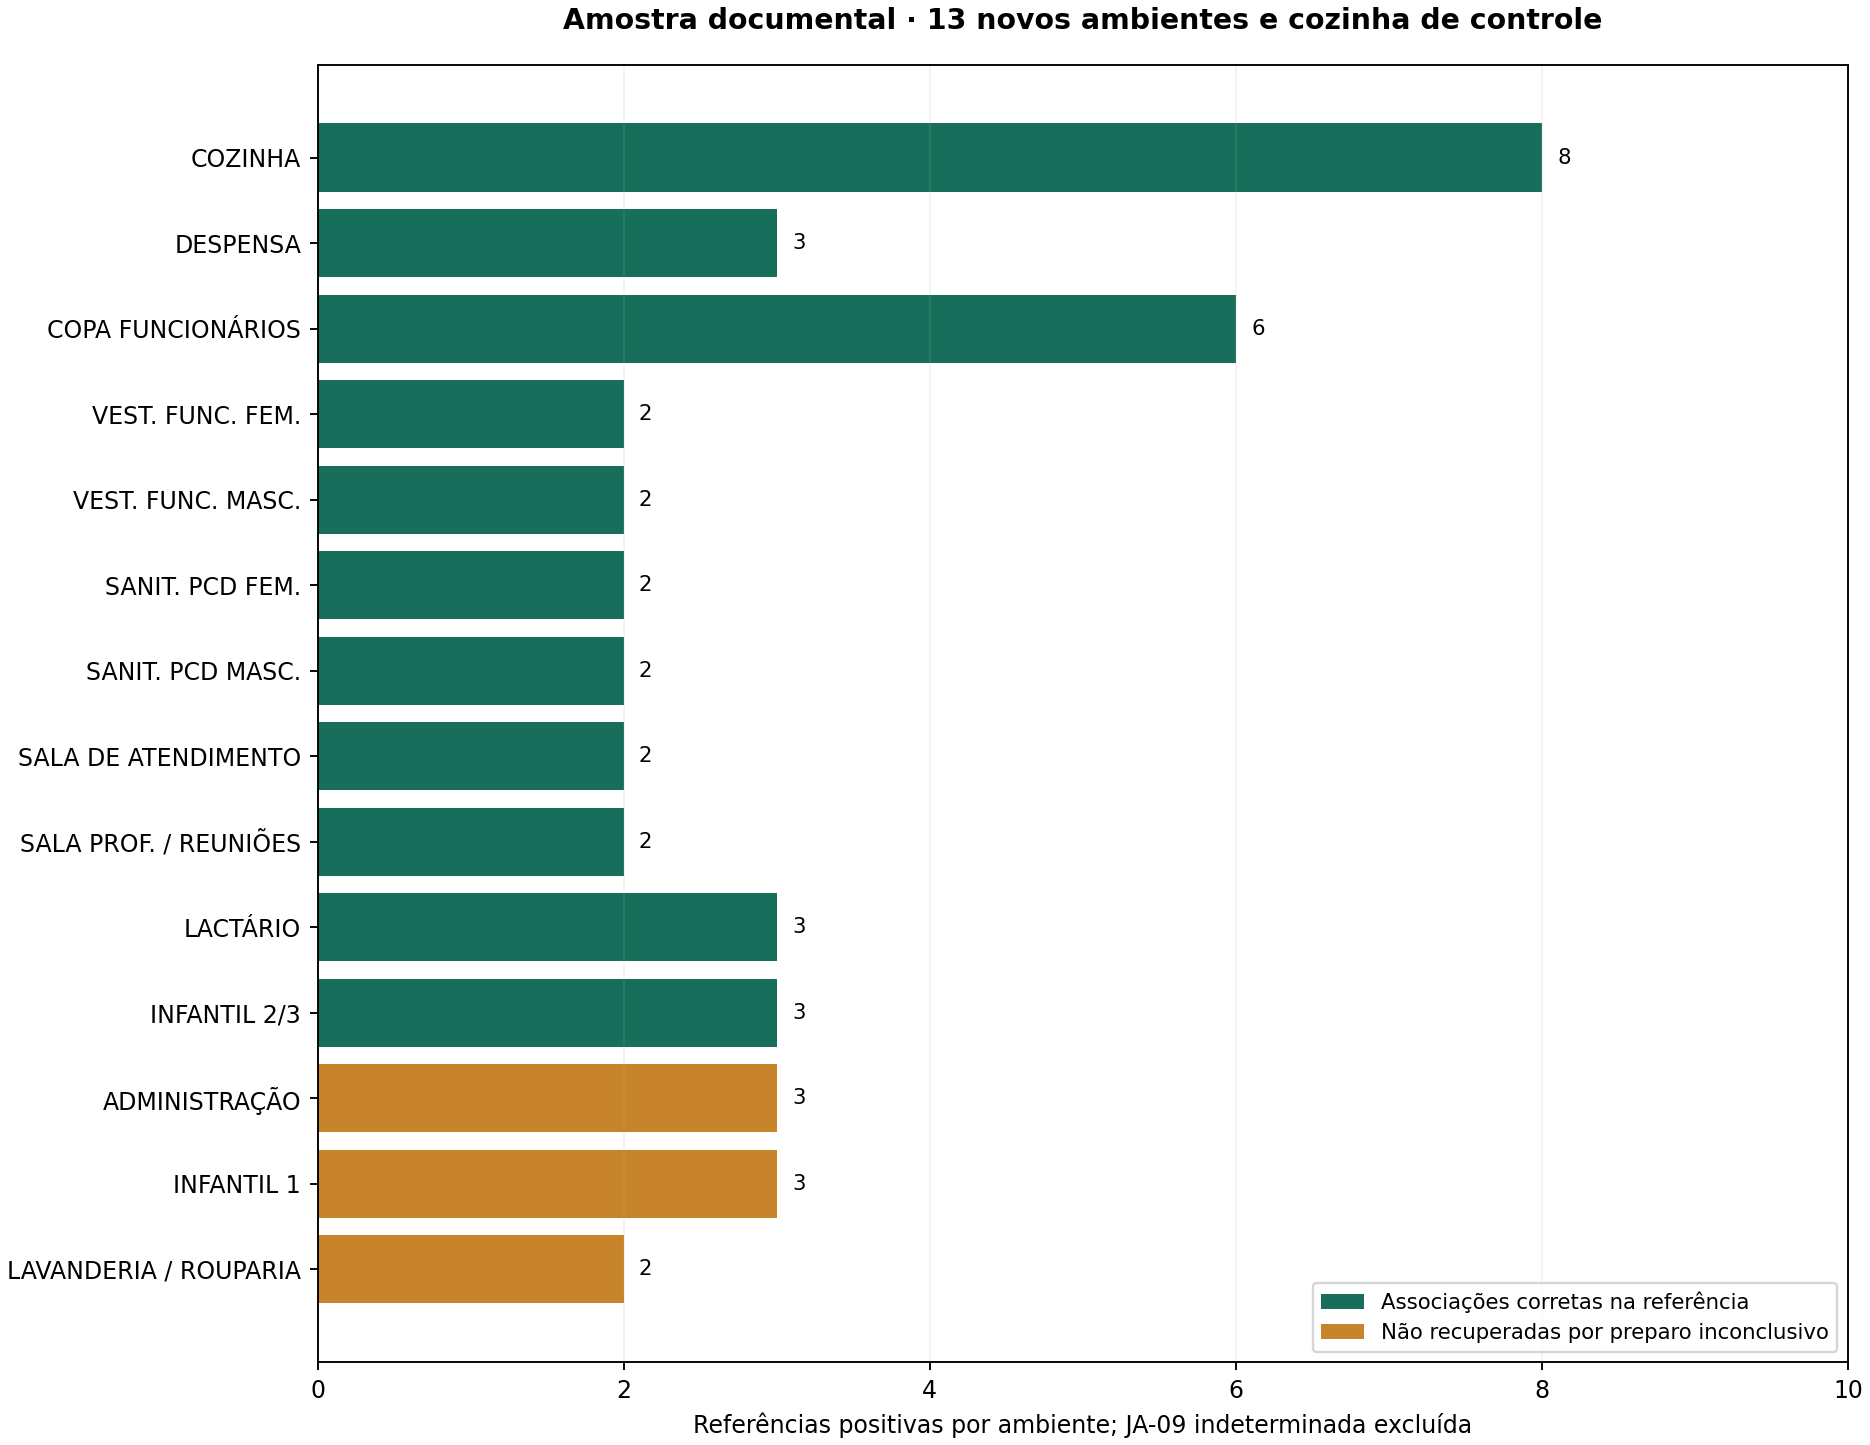

Relatório: C:\Users\prcgu\OneDrive\Documentos\ChatGPT\Artigo da Disciplina BIM\desenvolvimento\multiambientes_v01\execucao_notebook\resultados\Relatorio_Multiambientes_v09.html


In [7]:
from apresentar_lote import run as apresentar
apresentar(SAIDA)
from IPython.display import display,Image
display(Image(filename=str(SAIDA/'figuras/Cobertura_e_Conferencia_Multiambientes.png')))
display(Image(filename=str(SAIDA/'figuras/Conferencia_Por_Ambiente.png')))
print('Relatório:',SAIDA/'Relatorio_Multiambientes_v09.html')


## 8. Conclusão e integridade

**Há evidência de funcionamento além da cozinha em dez novos cômodos processados da amostra documental.** Nesses casos e na cozinha, foram confirmadas 35 associações e 33 exclusões, sem associação indevida ou omissão após a associação nos casos determinados.

**A cobertura ainda é limitada:** 12 dos 41 espaços não passaram no preparo. Na amostra, três deles concentram oito referências positivas não recuperadas. Incluindo essas falhas de cobertura, a recuperação é **35/43 = 81,4% nesta amostra intencional**, não uma estimativa estatística para todos os espaços ou outros edifícios. A JA-09 continua indeterminada documentalmente.

Vinte espaços chegaram à associação sem pendências registradas nesse recorte e nove com pendências. Quatro recortes de parede ficaram inconclusivos no módulo parcial; o fallback por caixa não foi portado. Doze pares de espaços aceitos apresentaram volume comum acima do limiar. Esses diagnósticos não foram corrigidos no IFC.

O próximo avanço metodológico é investigar o preparo dos 12 espaços, rever os quatro recortes inconclusivos e ampliar a conferência documental/independente. Não se declara validação exaustiva das 1.950 interfaces, de todas as paredes ou de todas as categorias.

**Reprodução:** o preparo global foi executado nesta revisão e preservado com hashes; estas células reexecutaram associação, diagnóstico OCP, avaliação, controles e integração. Conversão semântica e grafo anterior foram reutilizados explicitamente. Referências, PDFs originais, decisões e licenças acompanham o pacote.

In [8]:
assert sha(IFC)==IFC_SHA
referencia=json.loads((REF/'Referencia_Multiambientes_R03.json').read_text(encoding='utf8'))
assert all(sha(REF/p['arquivo'])==p['sha256'] for p in referencia['pranchas'])
fontes=json.loads((REF/'Fontes_Multiambientes_v09.json').read_text(encoding='utf8'))
assert all(sha(RAIZ/'codigo'/p['arquivo'])==p['sha256'] for p in fontes['arquivos'])
total=c1['aprovados']+c2['aprovados']+c3['aprovados']+sum(regressao.values())+c4['aprovados']
assert total==65
versoes={'python':sys.version,'numpy':numpy.__version__,'ifcopenshell':ifcopenshell.version,'OCP':OCP.__version__,'shapely':shapely.__version__,'rdflib':rdflib.__version__,'matplotlib':matplotlib.__version__}
verificacao={'snapshot':SNAPSHOT,'ifc_preservado':True,'controles_aprovados':total,'lote':lote,'conferencia':conferencia,'integracao':integracao,'preparo_reexecutado_nestas_celulas':REPROCESSAR_PREPARO,'versoes':versoes,'avaliacao_cega_por_especialista':False}
(SAIDA/'Verificacao_Final_v09.json').write_text(json.dumps(verificacao,ensure_ascii=False,indent=2),encoding='utf8')
print('APROVADO: 41 espaços registrados; 29 com associação e 12 inconclusivos; 65 controles; grafo reaberto e consultado.')
print('Conclusão limitada à amostra documental e à execução do mesmo IFC.')


APROVADO: 41 espaços registrados; 29 com associação e 12 inconclusivos; 65 controles; grafo reaberto e consultado.
Conclusão limitada à amostra documental e à execução do mesmo IFC.
